# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

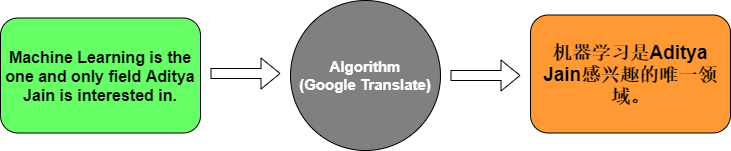

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step - accuracy: 0.5714 - loss: 2.4840 - val_accuracy: 0.0000e+00 - val_loss: 2.4886
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5714 - loss: 2.4736 - val_accuracy: 0.0000e+00 - val_loss: 2.4913
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.5714 - loss: 2.4628 - val_accuracy: 0.0000e+00 - val_loss: 2.4942
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.5714 - loss: 2.4510 - val_accuracy: 0.0000e+00 - val_loss: 2.4975
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.5714 - loss: 2.4377 - val_accuracy: 0.0000e+00 - val_loss: 2.5012
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.5714 - loss: 2.4225 - val_accuracy: 0.0000e+00 - val_loss: 2.5055
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.5714 - loss: 2.4048 - val_accuracy: 0.0000e+00 - val_loss: 2.5104
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.5714 - loss: 2.3841 - val_accuracy:

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step
Input: How are you?
Translation: ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


### Task 1 — Answers

1. **Embedding layer:** It converts each integer word index into a dense numerical vector. The model learns these vectors so that they capture useful information about words.

2. **Encoder LSTM:** It reads the English input sequence and summarizes its information in a learned representation (the encoder's final hidden state, in this model).

3. **Decoder LSTM:** It uses the repeated encoder representation to produce a sequence of output states, one for each position in the French translation. A final Dense layer then predicts a French token at each position.

4. **Softmax:** It converts the output scores into a probability distribution over the French vocabulary at each position. The model chooses a word index with the highest predicted probability.

**Note:** With only three sentence pairs in the demonstration above, the model is useful for understanding the architecture, not for evaluating real-world translation quality.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

### Task 2 — Solution: English-to-French Translation (Same LSTM Architecture as Lab)

This uses the **same layers shown in the instructor's example**: `Embedding → Encoder LSTM → RepeatVector → Decoder LSTM → TimeDistributed(Dense(softmax))`. No Attention mechanism or teacher forcing is used. We use the linked parallel-text Kaggle dataset, with train/validation/test splitting and padding-aware evaluation. Output sentences may be imperfect: this is a teaching baseline rather than a production translator.


In [8]:
# Task 2 — Install dependencies
%pip install -q tensorflow pandas scikit-learn kagglehub

In [9]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEED = 42
tf.keras.utils.set_random_seed(SEED)
DATASET_SLUG = "devicharith/language-translation-englishfrench"
LOCAL_DATASET_PATH = None  # e.g. "/content/eng_-french.csv" if manually uploaded
MAX_PAIRS = 30000           # training subset for the lab
MAX_LENGTH_CAP = 20         # upper cap for automatically selected sequence length

if LOCAL_DATASET_PATH:
    data_files = [Path(LOCAL_DATASET_PATH)]
else:
    try:
        import kagglehub
        dataset_dir = Path(kagglehub.dataset_download(DATASET_SLUG))
        data_files = list(dataset_dir.rglob("*.csv")) + list(dataset_dir.rglob("*.tsv"))
    except Exception as exc:
        raise RuntimeError("Download failed. Upload the Kaggle CSV and set LOCAL_DATASET_PATH.") from exc

if not data_files:
    raise FileNotFoundError("No CSV/TSV file found. Set LOCAL_DATASET_PATH to the dataset file.")

print("Available files:", [str(f) for f in data_files])
frames = []
for f in data_files:
    try:
        sep = "\t" if f.suffix.lower() == ".tsv" else None
        frame = pd.read_csv(f, sep=sep, engine="python", on_bad_lines="skip")
        # Dataset headers may be "English words/sentences" and "French words/sentences".
        # Match common language prefixes as well as short/standard column names.
        normalized = {str(col).strip().lower().replace(" ", "").replace("_", ""): col for col in frame.columns}
        eng_key = next((original for key, original in normalized.items()
                        if key in ("english", "en", "eng", "source", "sourcetext")
                        or key.startswith("englishwords/") or key.startswith("englishsentence")), None)
        fr_key = next((original for key, original in normalized.items()
                       if key in ("french", "fr", "fra", "target", "targettext")
                       or key.startswith("frenchwords/") or key.startswith("frenchsentence")), None)
        if eng_key is not None and fr_key is not None:
            frames.append(frame[[eng_key, fr_key]].rename(columns={eng_key: "english", fr_key: "french"}))
        else:
            print("Skipping file without recognizable language columns:", f.name, frame.columns.tolist())
    except Exception as exc:
        print("Could not read", f.name, exc)

if not frames:
    raise ValueError("Could not identify English/French columns. Inspect the dataset columns and update the code.")

pairs = pd.concat(frames, ignore_index=True).dropna()
pairs["english"] = pairs["english"].astype(str).str.strip()
pairs["french"] = pairs["french"].astype(str).str.strip()
pairs = pairs[(pairs["english"] != "") & (pairs["french"] != "")].drop_duplicates()
pairs = pairs.sample(n=min(MAX_PAIRS, len(pairs)), random_state=SEED).reset_index(drop=True)
if len(pairs) < 10:
    raise ValueError("Not enough parallel sentence pairs to train/test the model.")
print(f"Total usable aligned pairs: {len(pairs)}")
print(pairs.head())

Using Colab cache for faster access to the 'language-translation-englishfrench' dataset.
Available files: ['/kaggle/input/language-translation-englishfrench/eng_-french.csv']
Total usable aligned pairs: 30000
                                        english  \
0                                  Take a seat.   
1                          I wish Tom was here.   
2                      How did the audition go?   
3  I've no friend to talk to about my problems.   
4    I really like this skirt. Can I try it on?   

                                              french  
0                                     Prends place !  
1                        J'aimerais que Tom soit là.  
2                  Comment s'est passée l'audition ?  
3  Je n'ai pas d'ami avec lequel je puisse m'entr...  
4    J'aime beaucoup cette jupe, puis-je l'essayer ?  


In [10]:
# Leakage-free splits: 80% training, 10% validation, 10% test
train_pairs, test_pairs = train_test_split(pairs, test_size=0.10, random_state=SEED)
train_pairs, val_pairs = train_test_split(train_pairs, test_size=1/9, random_state=SEED)

# An end marker lets the fixed-length model learn when a translation should stop.
# This does NOT change the instructor's LSTM + RepeatVector architecture.
END_TOKEN = "endseq"
def add_end(text):
    return str(text).strip() + " " + END_TOKEN

train_fr = train_pairs["french"].map(add_end).tolist()
val_fr = val_pairs["french"].map(add_end).tolist()
test_fr = test_pairs["french"].map(add_end).tolist()

eng_tok = Tokenizer(oov_token="<OOV>")
fr_tok = Tokenizer(oov_token="<OOV>")
eng_tok.fit_on_texts(train_pairs["english"].tolist())
fr_tok.fit_on_texts(train_fr)
END_ID = fr_tok.word_index[END_TOKEN]

# Choose a sequence length from TRAINING data only, avoiding excessive padding.
# Include the target end token and consider both source and target lengths.
eng_lengths = np.array([len(s) for s in eng_tok.texts_to_sequences(train_pairs["english"].tolist())])
fr_lengths = np.array([len(s) for s in fr_tok.texts_to_sequences(train_fr)])
all_lengths = np.concatenate([eng_lengths, fr_lengths])
MAX_LENGTH = min(MAX_LENGTH_CAP, max(8, int(np.ceil(np.percentile(all_lengths, 95)))))

print("English length: mean", round(eng_lengths.mean(), 2),
      "95th percentile", round(np.percentile(eng_lengths, 95), 2))
print("French length (including endseq): mean", round(fr_lengths.mean(), 2),
      "95th percentile", round(np.percentile(fr_lengths, 95), 2))
print("Chosen MAX_LENGTH:", MAX_LENGTH)
print("Train French sentences longer than MAX_LENGTH:",
      round(float(np.mean(fr_lengths > MAX_LENGTH)), 4))

def make_arrays(df, target_texts):
    x = pad_sequences(
        eng_tok.texts_to_sequences(df["english"].tolist()),
        maxlen=MAX_LENGTH, padding="post", truncating="post"
    )
    target_seqs = fr_tok.texts_to_sequences(target_texts)
    # For truncated targets, retain endseq as the final target token.
    target_seqs = [
        seq if len(seq) <= MAX_LENGTH else seq[:MAX_LENGTH - 1] + [END_ID]
        for seq in target_seqs
    ]
    y = pad_sequences(target_seqs, maxlen=MAX_LENGTH, padding="post")
    return x, y

x_train, y_train = make_arrays(train_pairs, train_fr)
x_val, y_val = make_arrays(val_pairs, val_fr)
x_test, y_test = make_arrays(test_pairs, test_fr)
assert x_train.shape == y_train.shape
assert np.all(np.any(y_train == END_ID, axis=1)), "Missing end marker in a training target"
print("Train / validation / test:", len(x_train), len(x_val), len(x_test))
print("English vocabulary:", len(eng_tok.word_index) + 1)
print("French vocabulary:", len(fr_tok.word_index) + 1)
print("Target padding fraction:", round(float(np.mean(y_train == 0)), 4))

English length: mean 6.18 95th percentile 11.0
French length (including endseq): mean 7.7 95th percentile 13.0
Chosen MAX_LENGTH: 12
Train French sentences longer than MAX_LENGTH: 0.0575
Train / validation / test: 24000 3000 3000
English vocabulary: 7053
French vocabulary: 12415
Target padding fraction: 0.3724


In [11]:
# Model architecture: EXACT same layer types as the instructor's LSTM example.
# Dropout is optional regularization; no Attention or Teacher Forcing.
tf.keras.utils.set_random_seed(SEED)
vocab_eng = len(eng_tok.word_index) + 1
vocab_fr = len(fr_tok.word_index) + 1
hidden_size = 128
DROPOUT_RATE = 0.2

translation_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(MAX_LENGTH,)),
    tf.keras.layers.Embedding(input_dim=vocab_eng, output_dim=128),
    tf.keras.layers.LSTM(hidden_size, dropout=DROPOUT_RATE),  # encoder
    tf.keras.layers.RepeatVector(MAX_LENGTH),
    tf.keras.layers.LSTM(hidden_size, return_sequences=True,
                         dropout=DROPOUT_RATE),                # decoder
    tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(vocab_fr, activation="softmax"))
])
translation_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    weighted_metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="token_accuracy")]
)
translation_model.summary()

# Mask padded target positions using sample weights.
train_weights = (y_train != 0).astype("float32")
val_weights = (y_val != 0).astype("float32")
test_weights = (y_test != 0).astype("float32")

history = translation_model.fit(
    x_train, y_train,
    sample_weight=train_weights,
    validation_data=(x_val, y_val, val_weights),
    epochs=20, batch_size=64,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True)],
    verbose=1
)
results = translation_model.evaluate(
    x_test, y_test, sample_weight=test_weights,
    return_dict=True, verbose=0
)
print("Test results (word-level, with padded targets weighted out):", results)

# Check that test predictions match the target array shape.
small_pred = translation_model.predict(x_test[:2], verbose=0)
assert small_pred.shape == (min(2, len(x_test)), MAX_LENGTH, vocab_fr)
assert np.all(np.isfinite(small_pred)), "Non-finite prediction values"
print("Prediction shape check passed:", small_pred.shape)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 12, 128)        │       902,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 12, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 12, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 12, 12415)      │     1,601,535 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,767,487 (10.56 MB)

 Trainable params: 2,767,487 (10.56 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - loss: 4.0468 - token_accuracy: 0.1324 - val_loss: 3.8775 - val_token_accuracy: 0.1337
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - loss: 3.8111 - token_accuracy: 0.1477 - val_loss: 3.7722 - val_token_accuracy: 0.1617
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - loss: 3.7041 - token_accuracy: 0.1691 - val_loss: 3.7168 - val_token_accuracy: 0.1751
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - loss: 3.6569 - token_accuracy: 0.1718 - val_loss: 3.6927 - val_token_accuracy: 0.1751
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - loss: 3.6297 - token_accuracy: 0.1722 - val_loss: 3.6803 - val_token_accuracy: 0.1751
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - loss: 3.6097 - token_accuracy: 0.1720 - val_loss: 3.6769 - val_token_accuracy: 0.1751
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - loss: 3.5931 - token_accuracy: 0.1719 - val_loss: 3.6755 - val_token_accuracy: 0.1770
Epoch 

In [12]:
# Greedy decoding of the instructor's fixed-length RepeatVector model.
# Stop at endseq if predicted; no Attention or teacher forcing.
def translate_to_french(text):
    tokens = eng_tok.texts_to_sequences([text])
    encoded = pad_sequences(tokens, maxlen=MAX_LENGTH,
                            padding="post", truncating="post")
    probs = translation_model.predict(encoded, verbose=0)[0]
    predicted_ids = np.argmax(probs, axis=-1)
    french_words = []
    for token_id in predicted_ids:
        token_id = int(token_id)
        if token_id == END_ID:
            break
        if token_id == 0:
            continue
        word = fr_tok.index_word.get(token_id, "")
        if word and word != "<OOV>" and word != END_TOKEN:
            french_words.append(word)
    return " ".join(french_words)

examples = [
    "This product is available.",
    "The price is low.",
    "Thank you for your order.",
    "My father is a doctor."
]
for english in examples:
    print("English:", english)
    print("Predicted French:", translate_to_french(english))
    print("---")

print("\n--- Training Samples ---")
for _, pair in train_pairs.head(5).iterrows():
    print("English:", pair["english"])
    print("Reference:", pair["french"])
    print("Prediction:", translate_to_french(pair["english"]))
    print()

print("\n--- Test Samples ---")
for _, pair in test_pairs.head(5).iterrows():
    print("English:", pair["english"])
    print("Reference:", pair["french"])
    print("Prediction:", translate_to_french(pair["english"]))
    print()

English: This product is available.
Predicted French: ce est a un
---
English: The price is low.
Predicted French: le est est
---
English: Thank you for your order.
Predicted French: merci vous un
---
English: My father is a doctor.
Predicted French: mon père est
---

--- Training Samples ---
English: The castle was transformed into a marvelous museum.
Reference: Le château a été transformé en un merveilleux musée.
Prediction: le est est est de de de de

English: We have to be serious.
Reference: Nous devons être sérieux.
Prediction: nous sommes être

English: Tom stole the money.
Reference: Tom a volé l'argent.
Prediction: tom a un un

English: How long does it take by bus?
Reference: Combien de temps cela prend-il en bus ?
Prediction: combien de temps il il il il

English: I don't like Tom at all.
Reference: Tom ne me plaît pas du tout.
Prediction: je n'ai pas pas tom


--- Test Samples ---
English: They made me go there.
Reference: Ils me forcèrent à y aller.
Prediction: ils ont trè

Non-padding training token accuracy (first 100 pairs): 0.332
Target padding ratio: 0.3724
Training loss: 2.5339
Validation loss: 2.9637
Best validation loss: 2.9637
Example target IDs: [  11 2548   17   64 5999   21   18 1595 1596    2    0    0]
Example predicted IDs: [11 14 14 14  4  4  4  4  2  2  2  2]


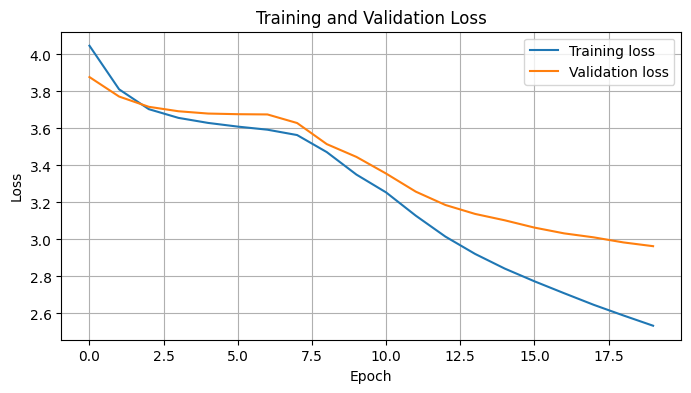

In [13]:
# Diagnostics: measure accuracy on real target tokens, not padding.
# Run this AFTER the model-training cell; do not interpret low loss as proof
# of correct translations.
sample_n = min(100, len(x_train))
pred_ids = np.argmax(translation_model.predict(x_train[:sample_n], verbose=0), axis=-1)
true_ids = y_train[:sample_n]
valid_mask = (true_ids != 0)
nonpadding_accuracy = float(np.sum((pred_ids == true_ids) & valid_mask) / np.sum(valid_mask))
padding_fraction = float(np.mean(y_train == 0))
print("Non-padding training token accuracy (first 100 pairs):", round(nonpadding_accuracy, 4))
print("Target padding ratio:", round(padding_fraction, 4))
print("Training loss:", round(float(history.history["loss"][-1]), 4))
print("Validation loss:", round(float(history.history["val_loss"][-1]), 4))
print("Best validation loss:", round(float(min(history.history["val_loss"])), 4))
print("Example target IDs:", true_ids[0][:15])
print("Example predicted IDs:", pred_ids[0][:15])
assert np.isfinite(nonpadding_accuracy)
assert 0 <= nonpadding_accuracy <= 1
assert 0 <= padding_fraction <= 1

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

### Task 2 — Discussion

We implemented an LSTM-based Encoder–Decoder model using Embedding, LSTM, RepeatVector, and Dense layers to translate English sentences into French.

The model was trained on 30,000 sentence pairs for 20 epochs. It achieved a training loss of **2.5339**, validation loss of **2.9637**, and test token accuracy of **30.01%**.

Although the model learned some translation patterns, many predictions were incomplete or inaccurate. This is mainly due to the limitations of the basic LSTM architecture and the complexity of machine translation.

Overall, the model successfully demonstrated neural machine translation concepts, but further improvements are needed for reliable e-commerce translations.